# cubic spline for interpolation and integration
we need a good splining algorithm in the TEM forward.
Here is some testing of cubic splines, and whether it is preferable to do it along the first axis or the last axis.
tests are indicating that is faster to spline along the first axis. to my surprise

### original implementation

In [4]:
import matplotlib.pyplot as plt
import numpy as np

class spline:
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.compute_coefficients()

    def compute_coefficients(self):
        x = self.x
        y = self.y

        n = len(x)

        x = np.pad(x, (1,0))# pretty sure this is just a dumb hack to get 1 indexing 

        frnt_pad = (1,0)
        back_pad = (0,1)
        if len(y.shape) == 3:
            frnt_pad = ((1,0), (0,0), (0,0))
            back_pad = ((0,1), (0,0), (0,0))
        y = np.pad(y, frnt_pad)


        # !.....Set up tridiagonal system.........................................
        # !.    b=diagonal, d=offdiagonal, c=right-hand side

        b = np.zeros(y.shape, dtype=y.dtype)
        c = np.zeros(y.shape, dtype=y.dtype)
        d = np.zeros(y.shape, dtype=y.dtype)

        d[1]=x[2]-x[1]
        c[2]=(y[2]-y[1])/d[1]
        for k in range(2,n):
            d[k]=x[k+1]-x[k]
            b[k]=2*(d[k-1]+d[k])
            c[k+1]=(y[k+1]-y[k])/d[k]
            c[k]=c[k+1]-c[k]

        #     !.....End conditions.  third derivatives at x[1] and x[n] obtained
        #     !.       from divided differences.......................................
        b[1]=-d[1]
        b[n]=-d[n-1]
        c[1]=0
        c[n]=0
        if n>3:
            c[1]=c[3]/(x[4]-x[2])-c[2]/(x[3]-x[1])
            c[n]=c[n-1]/(x[n]-x[n-2])-c[n-2]/(x[n-1]-x[n-3])
            c[1]=c[1]*d[1]*d[1]/(x[4]-x[1])
            c[n]=-c[n]*d[n-1]*d[n-1]/(x[n]-x[n-3])

        for k in range(2, n+1):#    ! forward elimination
            t=d[k-1]/b[k-1]
            b[k]=b[k]-t*d[k-1]
            c[k]=c[k]-t*c[k-1]

        c[n]=c[n]/b[n]#   ! back substitution [ makes c the sigma of text]
    #  DO k=n-1,1,-1
        for k in range(n-1, 0, -1):
            c[k]=(c[k]-d[k]*c[k+1])/b[k]

    # !.....Compute polynomial coefficients...................................
        b[n]=(y[n]-y[n-1])/d[n-1]+d[n-1]*(c[n-1]+c[n]+c[n])
        #DO k=1,n-1
        for k in range(1, n):
            b[k]=(y[k+1]-y[k])/d[k]-d[k]*(c[k+1]+c[k]+c[k])
            d[k]=(c[k+1]-c[k])/d[k]
            c[k]=3*c[k]
        c[n]=3*c[n]
        d[n]=d[n-1]

        self.a = y[1:]
        self.b = b[1:]
        self.c = c[1:]
        self.d = d[1:]

    def __call__(self, xnew):
        ix = np.searchsorted(self.x, xnew, side='right')-1
        dx = xnew-self.x[ix]
        return self.a[ix] + self.b[ix]*dx + self.c[ix]*dx*dx + self.d[ix]*dx**3


### First axis implementation

In [5]:
import matplotlib.pyplot as plt
import numpy as np

class spline0:
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.compute_coefficients()

    def compute_coefficients(self):
        x = self.x
        y = self.y

        n = len(x)-1

        # !.....Set up tridiagonal system.........................................
        # !.    b=diagonal, d=offdiagonal, c=right-hand side

        b = np.zeros(y.shape, dtype=y.dtype)
        c = np.zeros(y.shape, dtype=y.dtype)
        d = np.zeros(y.shape, dtype=y.dtype)

        d[0]=x[1]-x[0]
        c[1]=(y[1]-y[0])/d[0]

        for k in range(1,n):
            d[k]=x[k+1]-x[k]
            b[k]=2*(d[k-1]+d[k])
            c[k+1]=(y[k+1]-y[k])/d[k]
            c[k]=c[k+1]-c[k]

        #     !.....End conditions.  third derivatives at x[0] and x[n] obtained
        #     !.       from divided differences.......................................
        b[0]=-d[0]
        b[n]=-d[n-1]
        c[0]=0
        c[n]=0
        if n>3:
            c[0]=c[2]/(x[3]-x[1])-c[1]/(x[2]-x[0])
            c[n]=c[n-1]/(x[n]-x[n-2])-c[n-2]/(x[n-1]-x[n-3])
            c[0]=c[0]*d[0]*d[0]/(x[3]-x[0])
            c[n]=-c[n]*d[n-1]*d[n-1]/(x[n]-x[n-3])

        for k in range(1, n+1):#    ! forward elimination
            t=d[k-1]/b[k-1]
            b[k]=b[k]-t*d[k-1]
            c[k]=c[k]-t*c[k-1]

        c[n]=c[n]/b[n]#   ! back substitution [ makes c the sigma of text]
        for k in range(n-1, -1, -1):
            c[k]=(c[k]-d[k]*c[k+1])/b[k]

    # !.....Compute polynomial coefficients...................................
        b[n]=(y[n]-y[n-1])/d[n-1]+d[n-1]*(c[n-1]+c[n]+c[n])
        #DO k=1,n-1
        for k in range(n):
            b[k]=(y[k+1]-y[k])/d[k]-d[k]*(c[k+1]+c[k]+c[k])
            d[k]=(c[k+1]-c[k])/d[k]
            c[k]=3*c[k]
        c[n]=3*c[n]
        d[n]=d[n-1]

        self.a = y
        self.b = b
        self.c = c
        self.d = d

    def __call__(self, xnew):
        ix = np.searchsorted(self.x, xnew, side='right')-1
        dx = (xnew-self.x[ix])[:, None]
        return self.a[ix] + self.b[ix]*dx + self.c[ix]*dx*dx + self.d[ix]*dx**3

### last axis implementation

In [157]:
import matplotlib.pyplot as plt
import numpy as np

class spline1:
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.compute_coefficients()

    def compute_coefficients(self):
        x = self.x
        y = self.y

        n = len(x)-1

        # !.....Set up tridiagonal system.........................................
        # !.    b=diagonal, d=offdiagonal, c=right-hand side

        b = np.zeros(y.shape, dtype=y.dtype)
        c = np.zeros(y.shape, dtype=y.dtype)
        d = np.zeros(y.shape, dtype=y.dtype)

        d[..., :-1] = np.diff(x)[..., :]
        b[..., 1:]  = 2*(d[..., :-1]+d[..., 1:])
        c[..., 1:]  = np.diff(y, axis=-1)/d[..., :-1]
        c[..., :-1] = np.diff(c, axis=-1)

        #     !.....End conditions.  third derivatives at x[..., 0] and x[..., n] obtained
        #     !.       from divided differences.......................................
        b[..., 0]=-d[..., 0]
        b[..., n]=-d[..., n-1]
        c[..., 0]=0
        c[..., n]=0
        if n>3:
            c[..., 0]=c[..., 2]/(x[..., 3]-x[..., 1])-c[..., 1]/(x[..., 2]-x[..., 0])
            c[..., n]=c[..., n-1]/(x[..., n]-x[..., n-2])-c[..., n-2]/(x[..., n-1]-x[..., n-3])
            c[..., 0]=c[..., 0]*d[..., 0]*d[..., 0]/(x[..., 3]-x[..., 0])
            c[..., n]=-c[..., n]*d[..., n-1]*d[..., n-1]/(x[..., n]-x[..., n-3])

        for k in range(1, n+1):#    ! forward elimination
            t=d[..., k-1]/b[..., k-1]
            b[..., k]=b[..., k]-t*d[..., k-1]
            c[..., k]=c[..., k]-t*c[..., k-1]

        c[..., n]=c[..., n]/b[..., n]#   ! back substitution [...,  makes c the sigma of text]
        for k in range(n-1, -1, -1):
            c[..., k]=(c[..., k]-d[..., k]*c[..., k+1])/b[..., k]

    # !.....Compute polynomial coefficients...................................
        b[..., n]=(y[..., n]-y[..., n-1])/d[..., n-1]+d[..., n-1]*(c[..., n-1]+c[..., n]+c[..., n])
        #DO k=1,n-1
        for k in range(n):
            b[..., k]=(y[..., k+1]-y[..., k])/d[..., k]-d[..., k]*(c[..., k+1]+c[..., k]+c[..., k])
            d[..., k]=(c[..., k+1]-c[..., k])/d[..., k]
            c[..., k]=3*c[..., k]
        c[..., n]=3*c[..., n]
        d[..., n]=d[..., n-1]

        self.a = y
        self.b = b
        self.c = c
        self.d = d

    def __call__(self, xnew):
        ix = np.searchsorted(self.x, xnew, side='right')-1
        dx = (xnew-self.x[ix])[None, :]
        return self.a[..., ix] + self.b[..., ix]*dx + self.c[..., ix]*dx*dx + self.d[..., ix]*dx**3

### first axis with some optimization

In [158]:
import matplotlib.pyplot as plt
import numpy as np

class spline01:
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.compute_coefficients()

    def compute_coefficients(self):
        x = self.x
        y = self.y

        n = len(x)-1

        # !.....Set up tridiagonal system.........................................
        # !.    b=diagonal, d=offdiagonal, c=right-hand side

        b = np.zeros(y.shape, dtype=y.dtype)
        c = np.zeros(y.shape, dtype=y.dtype)
        d = np.zeros(y.shape, dtype=y.dtype)

        d[:-1] = np.diff(x)[:, ..., None]
        b[1:]  = 2*(d[:-1]+d[1:])
        c[1:]  = np.diff(y, axis=0)/d[:-1]
        c[:-1] = np.diff(c, axis=0)

        b[0]=-d[0]
        b[n]=-d[n-1]
        c[0]=0
        c[n]=0
        if n>3:
            c[0]=c[2]/(x[3]-x[1])-c[1]/(x[2]-x[0])
            c[n]=c[n-1]/(x[n]-x[n-2])-c[n-2]/(x[n-1]-x[n-3])
            c[0]=c[0]*d[0]*d[0]/(x[3]-x[0])
            c[n]=-c[n]*d[n-1]*d[n-1]/(x[n]-x[n-3])

        for k in range(1, n+1):#    ! forward elimination
            t=d[k-1]/b[k-1]
            b[k]=b[k]-t*d[k-1]
            c[k]=c[k]-t*c[k-1]

        c[n]=c[n]/b[n]#   ! back substitution [ makes c the sigma of text]
        for k in range(n-1, -1, -1):
            c[k]=(c[k]-d[k]*c[k+1])/b[k]

    # !.....Compute polynomial coefficients...................................
        b[n]=(y[n]-y[n-1])/d[n-1]+d[n-1]*(c[n-1]+c[n]+c[n])
        #DO k=1,n-1
        for k in range(n):
            b[k]=(y[k+1]-y[k])/d[k]-d[k]*(c[k+1]+c[k]+c[k])
            d[k]=(c[k+1]-c[k])/d[k]
            c[k]=3*c[k]
        c[n]=3*c[n]
        d[n]=d[n-1]

        self.a = y
        self.b = b
        self.c = c
        self.d = d

    def __call__(self, xnew):
        ix = np.searchsorted(self.x, xnew, side='right')-1
        dx = (xnew-self.x[ix])[:, None]
        return self.a[ix] + self.b[ix]*dx + self.c[ix]*dx*dx + self.d[ix]*dx**3

In [159]:
x = np.linspace(0, 10, 4*8000+1)
xs = x[::4]

f = lambda x: 1+x**2 + 2*x**3

ys = f(xs)
ys = ys[None, :] + np.arange(650)[:, None]

y = f(x)
y = y[None, :] + np.arange(650)[:, None]

In [160]:
yt = ys.T

In [148]:
from scipy.interpolate import interp1d
scpy = interp1d(xs, ys, kind='cubic')

In [149]:
%%timeit 

y2 = scpy(x)

95.3 ms ± 5.02 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [150]:
cspl = spline01(xs,yt)
y2 = cspl(x)
np.allclose(y.T, y2)

# previous 89.2ms

True

In [165]:
%timeit cspl = spline01(xs,yt)# 1/3
%timeit y2   = cspl(x)# 2/3

444 ms ± 54.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
717 ms ± 105 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [163]:
%%timeit
cspl = spline1(xs,ys)
y2 = cspl(x)

2.02 s ± 154 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [153]:
cspl = spline0(xs,yt)

In [154]:
%%timeit

y2 = cspl(x)

559 ms ± 34.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [141]:
x = np.linspace(0, 10, 57+4*8)
xs = x[::4]

f = lambda x: 1+x**2 + 2*x**3

ys = f(xs)
ys = ys[None, :] + np.arange(6)[:, None]

y = f(x)
y = y[None, :] + np.arange(6)[:, None]


cspl = spline01(xs,ys)
y2 = cspl(x)



plt.figure()
plt.plot(x,y, '.-')
plt.plot(xs, ys, 'r.')
plt.plot(x, y2, 'x')


ValueError: could not broadcast input array from shape (22,1) into shape (5,23)

ValueError: x and y must have same first dimension, but have shapes (89,) and (6, 89)

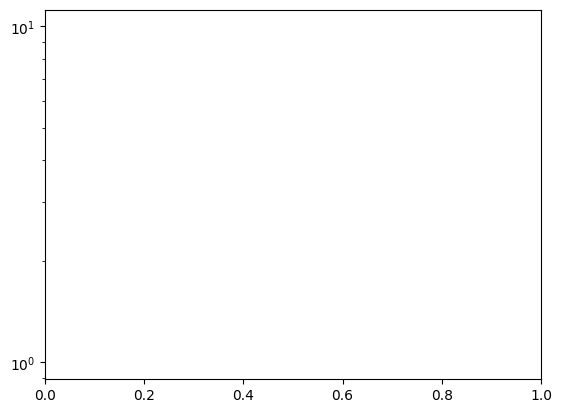

In [85]:
plt.figure()
plt.semilogy(x, np.abs(y2-y))

In [73]:
np.allclose(y, y2)

True